# LoRA Fine-Tuning of TinyLlama-1.1B for Software Vulnerability Detection

**Dataset:** Devign (CodeXGLUE defect detection)



In [ ]:
!pip install -q -U transformers peft datasets accelerate bitsandbytes scikit-learn matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 64.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 555.1/555.1 kB 26.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 389.2/389.2 kB 13.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.7/60.7 MB 17.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 79.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 77.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.9/48.9 MB 12.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sklearn-compat 0.1.5 requires scikit-learn<1.9,>=1.2, but you have scikit-learn 1.9.0 which is incompatible.


In [ ]:
import os, re, json, random, zipfile
import numpy as np
import torch
import matplotlib
import matplotlib.pyplot as plt
from datasets import load_dataset, Dataset
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, roc_curve, auc)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

CONFIG = {
    "model_name": "TinyLlama/TinyLlama-1.1B-Chat-v1.0",
    "train_samples": 4000,
    "val_samples": 1000,
    "test_samples": 1000,
    "MAX_LEN": 512,
    "BATCH_SIZE": 4,
    "GRAD_ACCUM": 4,
    "EPOCHS": 2,
    "LR": 2e-4,
    "lora_r": 16,
    "lora_alpha": 32,
    "lora_dropout": 0.05
}

os.makedirs("figures", exist_ok=True)
matplotlib.rcParams["figure.dpi"] = 110
FIG_KW = dict(dpi=300, bbox_inches="tight")

assert torch.cuda.is_available(), "No GPU found — set Runtime > Change runtime type > T4 GPU"
print("GPU:", torch.cuda.get_device_name(0))

GPU: Tesla T4


## 1. Dataset: Devign (CodeXGLUE defect detection)
27,318 manually labeled C functions from FFmpeg and QEMU. Binary label: 1 = vulnerable, 0 = safe.

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/5.60k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/17.8M [00:00<?, ?B/s]

data/validation-00000-of-00001.parquet:   0%|          | 0.00/2.21M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/2.23M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/21854 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2732 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2732 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'func', 'target', 'project', 'commit_id'],
        num_rows: 21854
    })
    validation: Dataset({
        features: ['id', 'func', 'target', 'project', 'commit_id'],
        num_rows: 2732
    })
    test: Dataset({
        features: ['id', 'func', 'target', 'project', 'commit_id'],
        num_rows: 2732
    })
})
train: 21854 functions, 10018 vulnerable (45.8%)
validation: 2732 functions, 1187 vulnerable (43.4%)
test: 2732 functions, 1255 vulnerable (45.9%)


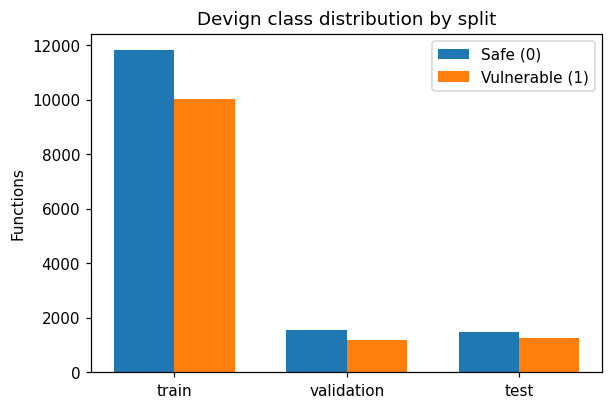

In [ ]:
raw = load_dataset("google/code_x_glue_cc_defect_detection")
print(raw)

dataset_stats = {}
for split in ["train", "validation", "test"]:
    labels = raw[split]["target"]
    n_vuln = int(sum(labels)); n = len(labels)
    dataset_stats[split] = {"total": n, "vulnerable": n_vuln, "safe": n - n_vuln}
    print(f"{split}: {n} functions, {n_vuln} vulnerable ({100*n_vuln/n:.1f}%)")

fig, ax = plt.subplots(figsize=(6, 4))
splits = list(dataset_stats.keys())
x = np.arange(len(splits)); w = 0.35
ax.bar(x - w/2, [dataset_stats[s]["safe"] for s in splits], w, label="Safe (0)")
ax.bar(x + w/2, [dataset_stats[s]["vulnerable"] for s in splits], w, label="Vulnerable (1)")
ax.set_xticks(x); ax.set_xticklabels(splits)
ax.set_ylabel("Functions"); ax.set_title("Devign class distribution by split")
ax.legend()
plt.savefig("figures/fig1_dataset_distribution.png", **FIG_KW)
plt.show()

## 2. Preprocessing & feature engineering
Steps: (1) strip comments, (2) normalize whitespace, (3) drop duplicates/empties, (4) analyze token lengths, (5) stratified subsampling.

In [ ]:
def clean_code(code):
    code = re.sub(r"/\*.*?\*/", " ", code, flags=re.DOTALL)  # block comments
    code = re.sub(r"//[^\n]*", " ", code)                    # line comments
    code = re.sub(r"[ \t]+", " ", code)                      # collapse spaces/tabs
    code = re.sub(r"\n\s*\n+", "\n", code)                   # collapse blank lines
    return code.strip()

def preprocess_split(split, n_keep):
    seen, rows = set(), []
    for ex in raw[split]:
        c = clean_code(ex["func"])
        if len(c) < 20:
            continue
        h = hash(c)
        if h in seen:
            continue
        seen.add(h)
        rows.append({"code": c, "label": int(ex["target"])})
    random.Random(SEED).shuffle(rows)
    # stratified subsample
    pos = [r for r in rows if r["label"] == 1]
    neg = [r for r in rows if r["label"] == 0]
    ratio = len(pos) / len(rows)
    n_pos = min(len(pos), int(round(n_keep * ratio)))
    n_neg = min(len(neg), n_keep - n_pos)
    out = pos[:n_pos] + neg[:n_neg]
    random.Random(SEED).shuffle(out)
    return rows, out

full_train, train_rows = preprocess_split("train", CONFIG["train_samples"])
_, val_rows = preprocess_split("validation", CONFIG["val_samples"])
_, test_rows = preprocess_split("test", CONFIG["test_samples"])

preproc_stats = {
    "train_after_dedup": len(full_train),
    "train_used": len(train_rows),
    "val_used": len(val_rows),
    "test_used": len(test_rows),
    "train_vuln_pct": round(100 * float(np.mean([r["label"] for r in train_rows])), 2)
}
print(json.dumps(preproc_stats, indent=2))

{
  "train_after_dedup": 21795,
  "train_used": 4000,
  "val_used": 1000,
  "test_used": 1000,
  "train_vuln_pct": 45.8
}


config.json:   0%|          | 0.00/608 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.29k [00:00<?, ?B/s]

tokenizer.model:   0%|          | 0.00/500k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.84M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/551 [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (3106 > 2048). Running this sequence through the model will result in indexing errors


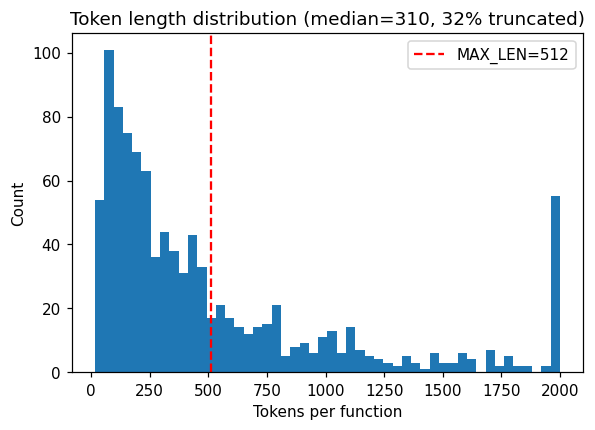

In [ ]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(CONFIG["model_name"])
tokenizer.pad_token = tokenizer.eos_token

lengths = [len(tokenizer(r["code"]).input_ids) for r in random.Random(0).sample(train_rows, 1000)]
pct_truncated = 100 * float(np.mean(np.array(lengths) > CONFIG["MAX_LEN"]))
preproc_stats["median_token_len"] = int(np.median(lengths))
preproc_stats["pct_truncated_at_max_len"] = round(pct_truncated, 1)

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(np.clip(lengths, 0, 2000), bins=50)
ax.axvline(CONFIG["MAX_LEN"], color="red", linestyle="--", label=f"MAX_LEN={CONFIG['MAX_LEN']}")
ax.set_xlabel("Tokens per function"); ax.set_ylabel("Count")
ax.set_title(f"Token length distribution (median={preproc_stats['median_token_len']}, {pct_truncated:.0f}% truncated)")
ax.legend()
plt.savefig("figures/fig2_token_lengths.png", **FIG_KW)
plt.show()

## 3. Baseline: TF-IDF + Logistic Regression
Classical feature-engineering baseline to compare against the LoRA-tuned LLM.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

vec = TfidfVectorizer(max_features=20000,
                      token_pattern=r"[A-Za-z_][A-Za-z0-9_]*|[^\sA-Za-z0-9]",
                      ngram_range=(1, 2), sublinear_tf=True)
Xtr = vec.fit_transform([r["code"] for r in train_rows])
Xte = vec.transform([r["code"] for r in test_rows])
ytr = [r["label"] for r in train_rows]
yte = [r["label"] for r in test_rows]

clf = LogisticRegression(max_iter=2000, C=1.0, random_state=SEED).fit(Xtr, ytr)
base_pred = clf.predict(Xte)
base_prob = clf.predict_proba(Xte)[:, 1]

bp, br, bf, _ = precision_recall_fscore_support(yte, base_pred, average="binary")
baseline_metrics = {"accuracy": accuracy_score(yte, base_pred),
                    "precision": bp, "recall": br, "f1": bf}
print({k: round(float(v), 4) for k, v in baseline_metrics.items()})

{'accuracy': 0.603, 'precision': 0.5912, 'recall': 0.4379, 'f1': 0.5031}


## 4. LoRA fine-tuning of TinyLlama-1.1B (4-bit QLoRA)

In [ ]:
def tokenize(batch):
    return tokenizer(batch["code"], truncation=True, max_length=CONFIG["MAX_LEN"])

ds_train = Dataset.from_list(train_rows).map(tokenize, batched=True, remove_columns=["code"])
ds_val = Dataset.from_list(val_rows).map(tokenize, batched=True, remove_columns=["code"])
ds_test = Dataset.from_list(test_rows).map(tokenize, batched=True, remove_columns=["code"])
print(ds_train)

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Dataset({
    features: ['label', 'input_ids', 'attention_mask'],
    num_rows: 4000
})


In [ ]:
from transformers import (AutoModelForSequenceClassification, BitsAndBytesConfig,
                          TrainingArguments, Trainer, DataCollatorWithPadding)
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16
)

model = AutoModelForSequenceClassification.from_pretrained(
    CONFIG["model_name"], num_labels=2,
    quantization_config=bnb_config, device_map="auto"
)
model.config.pad_token_id = tokenizer.pad_token_id
model = prepare_model_for_kbit_training(model)

lora_config = LoraConfig(
    task_type="SEQ_CLS",
    r=CONFIG["lora_r"], lora_alpha=CONFIG["lora_alpha"], lora_dropout=CONFIG["lora_dropout"],
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj"],
    modules_to_save=["score"]
)
model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
param_stats = {"trainable_params": int(trainable), "total_params": int(total),
               "trainable_pct": round(100 * trainable / total, 4)}

model.safetensors:   0%|          | 0.00/2.20G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/bitsandbytes/backends/cuda/ops.py:213: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)
[transformers] LlamaForSequenceClassification LOAD REPORT from: TinyLlama/TinyLlama-1.1B-Chat-v1.0
Key            | Status     | 
---------------+------------+-
lm_head.weight | UNEXPECTED | 
score.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 4,509,696 || all params: 1,039,026,176 || trainable%: 0.4340


In [ ]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    p, r, f, _ = precision_recall_fscore_support(labels, preds, average="binary", zero_division=0)
    return {"accuracy": accuracy_score(labels, preds), "precision": p, "recall": r, "f1": f}

args = TrainingArguments(
    output_dir="lora_out",
    num_train_epochs=CONFIG["EPOCHS"],
    per_device_train_batch_size=CONFIG["BATCH_SIZE"],
    per_device_eval_batch_size=CONFIG["BATCH_SIZE"] * 2,
    gradient_accumulation_steps=CONFIG["GRAD_ACCUM"],
    learning_rate=CONFIG["LR"],
    warmup_ratio=0.06,
    fp16=True,
    logging_steps=10,
    eval_strategy="epoch",
    save_strategy="no",
    report_to="none",
    seed=SEED
)

trainer = Trainer(
    model=model, args=args,
    train_dataset=ds_train, eval_dataset=ds_val,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics
)

train_result = trainer.train()
print(train_result)

[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.
[transformers] `use_return_dict` is deprecated! Use `return_dict` instead!
/usr/local/lib/python3.12/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,2.928698,0.732813,0.591000,0.579618,0.209677,0.307953
2,2.493140,0.718944,0.582000,0.521622,0.444700,0.480100


/usr/local/lib/python3.12/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


TrainOutput(global_step=500, training_loss=2.7810121154785157, metrics={'train_runtime': 2636.8623, 'train_samples_per_second': 3.034, 'train_steps_per_second': 0.19, 'total_flos': 2.248358113438925e+16, 'train_loss': 2.7810121154785157, 'epoch': 2.0})


## 5. Evaluation on the held-out test set

In [ ]:
pred_out = trainer.predict(ds_test)
logits = pred_out.predictions
y_true = pred_out.label_ids
y_pred = np.argmax(logits, axis=-1)
probs = torch.softmax(torch.tensor(logits, dtype=torch.float32), dim=-1)[:, 1].numpy()

p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="binary")
lora_metrics = {"accuracy": float(accuracy_score(y_true, y_pred)),
                "precision": float(p), "recall": float(r), "f1": float(f)}
print("LoRA model:", {k: round(v, 4) for k, v in lora_metrics.items()})
print("Baseline:  ", {k: round(float(v), 4) for k, v in baseline_metrics.items()})

LoRA model: {'accuracy': 0.568, 'precision': 0.5372, 'recall': 0.4248, 'f1': 0.4745}
Baseline:   {'accuracy': 0.603, 'precision': 0.5912, 'recall': 0.4379, 'f1': 0.5031}


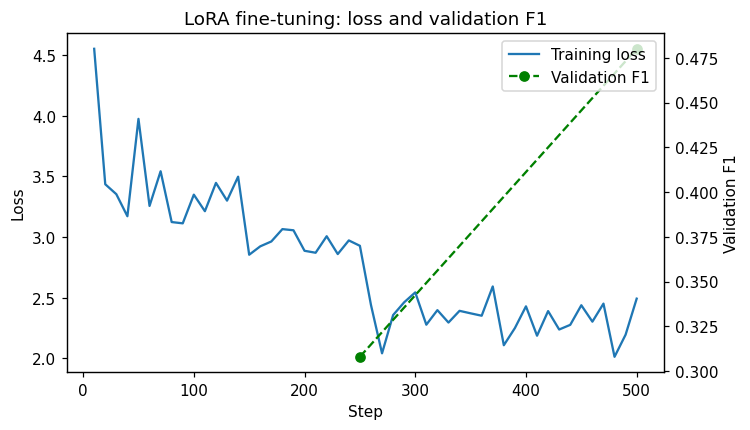

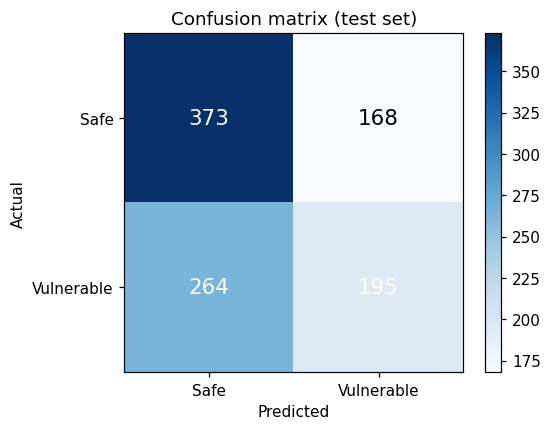

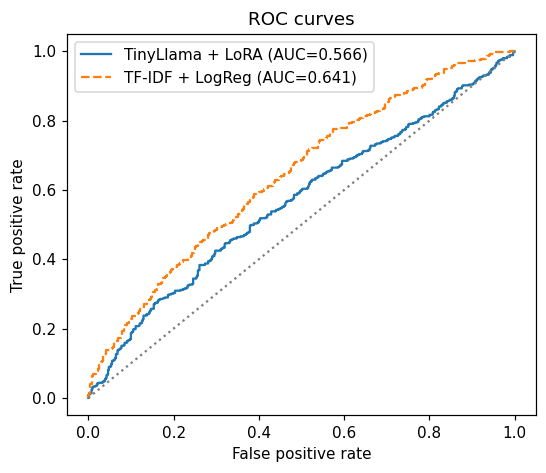

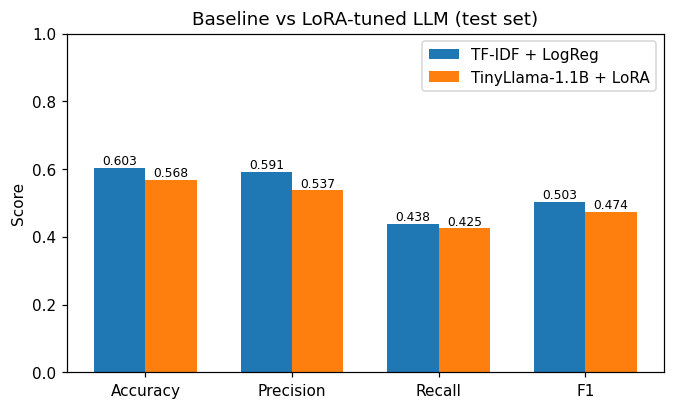

In [ ]:
# Fig 3: training loss curve + validation F1
logs = trainer.state.log_history
steps = [l["step"] for l in logs if "loss" in l]
losses = [l["loss"] for l in logs if "loss" in l]
eval_logs = [l for l in logs if "eval_f1" in l]

fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.plot(steps, losses, label="Training loss")
ax1.set_xlabel("Step"); ax1.set_ylabel("Loss")
ax2 = ax1.twinx()
ax2.plot([l["step"] for l in eval_logs], [l["eval_f1"] for l in eval_logs],
         "o--", color="green", label="Validation F1")
ax2.set_ylabel("Validation F1")
ax1.set_title("LoRA fine-tuning: loss and validation F1")
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.88))
plt.savefig("figures/fig3_loss_curve.png", **FIG_KW)
plt.show()

# Fig 4: confusion matrix
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                color="white" if cm[i, j] > cm.max()/2 else "black", fontsize=14)
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(["Safe", "Vulnerable"]); ax.set_yticklabels(["Safe", "Vulnerable"])
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title("Confusion matrix (test set)")
plt.colorbar(im)
plt.savefig("figures/fig4_confusion_matrix.png", **FIG_KW)
plt.show()

# Fig 5: ROC curves
fpr_l, tpr_l, _ = roc_curve(y_true, probs)
fpr_b, tpr_b, _ = roc_curve(yte, base_prob)
auc_l, auc_b = auc(fpr_l, tpr_l), auc(fpr_b, tpr_b)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.plot(fpr_l, tpr_l, label=f"TinyLlama + LoRA (AUC={auc_l:.3f})")
ax.plot(fpr_b, tpr_b, "--", label=f"TF-IDF + LogReg (AUC={auc_b:.3f})")
ax.plot([0, 1], [0, 1], ":", color="gray")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("ROC curves"); ax.legend()
plt.savefig("figures/fig5_roc_curves.png", **FIG_KW)
plt.show()

# Fig 6: metric comparison bar chart
names = ["accuracy", "precision", "recall", "f1"]
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(names)); w = 0.35
ax.bar(x - w/2, [baseline_metrics[m] for m in names], w, label="TF-IDF + LogReg")
ax.bar(x + w/2, [lora_metrics[m] for m in names], w, label="TinyLlama-1.1B + LoRA")
ax.set_xticks(x); ax.set_xticklabels([n.capitalize() for n in names])
ax.set_ylim(0, 1); ax.set_ylabel("Score")
ax.set_title("Baseline vs LoRA-tuned LLM (test set)")
ax.legend()
for i, m in enumerate(names):
    ax.text(i - w/2, baseline_metrics[m] + 0.01, f"{baseline_metrics[m]:.3f}", ha="center", fontsize=8)
    ax.text(i + w/2, lora_metrics[m] + 0.01, f"{lora_metrics[m]:.3f}", ha="center", fontsize=8)
plt.savefig("figures/fig6_model_comparison.png", **FIG_KW)
plt.show()

## 6. Export results package
Downloads `results_package.zip` (all figures + `results.json`) for the write-up.

In [ ]:
results = {
    "config": CONFIG,
    "dataset_stats": dataset_stats,
    "preprocessing": preproc_stats,
    "param_stats": param_stats,
    "train_runtime_sec": float(train_result.metrics.get("train_runtime", 0)),
    "baseline_metrics": {k: float(v) for k, v in baseline_metrics.items()},
    "lora_metrics": lora_metrics,
    "auc": {"lora": float(auc_l), "baseline": float(auc_b)},
    "confusion_matrix": cm.tolist(),
    "log_history": trainer.state.log_history
}
with open("figures/results.json", "w") as fjson:
    json.dump(results, fjson, indent=2)

with zipfile.ZipFile("results_package.zip", "w") as z:
    for fn in os.listdir("figures"):
        z.write(os.path.join("figures", fn), fn)
print("Wrote results_package.zip with:", os.listdir("figures"))

try:
    from google.colab import files
    files.download("results_package.zip")
except ImportError:
    print("Not in Colab — download results_package.zip manually.")

Wrote results_package.zip with: ['fig6_model_comparison.png', 'fig2_token_lengths.png', 'fig1_dataset_distribution.png', 'results.json', 'fig3_loss_curve.png', 'fig5_roc_curves.png', 'fig4_confusion_matrix.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>